# Anchor: quantum-checked brain-shift correction

Once the skull is opened, the brain sags, so the MRI that surgical navigation relies on goes stale by millimetres to centimetres. To fix the map, the system matches landmarks seen in live ultrasound to the same landmarks in the MRI and warps the map. **One wrong match bends the whole corrected map.**

Anchor decides **which matches to trust**. It treats that choice as a maximum-clique problem written as a QUBO, then solves it four ways:
- classical exact and heuristic solvers;
- gate-based QAOA;
- digitized annealing on gate hardware;
- a quantum annealer.

It scores every answer the same way: map error in mm at expert landmarks the solver never saw.

This notebook walks through the pipeline on real patient data (RESECT, 22 patients, CC BY 4.0), then loads the full benchmark, the noise study and any recorded hardware runs.

In [1]:
import sys, json, pathlib
ROOT = pathlib.Path.cwd().parent if pathlib.Path.cwd().name == "notebooks" else pathlib.Path.cwd()
sys.path.insert(0, str(ROOT / "backend"))
import numpy as np
from IPython.display import Image, display
from anchor.data import load_case, list_cases
from anchor.candidates import make_problem
from anchor.solvers import make_instance
print(len(list_cases()), "RESECT patients")

22 RESECT patients


## 1. Real brain shift
Each patient has about 15 landmark pairs that experts placed in the pre-op MRI and in the ultrasound taken after the skull was opened. The difference between the two is the brain shift.

In [2]:
case = load_case("Case12")
print(f"{case.case_id}: {case.n} landmark pairs, shift mean {case.shift_mm.mean():.1f} mm, max {case.shift_mm.max():.1f} mm")
allc = [load_case(c) for c in list_cases()]
print(f"All 22 patients: mean shift {np.mean([c.shift_mm.mean() for c in allc]):.2f} mm (RESECT paper reports about 5.4 mm)")

Case12: 16 landmark pairs, shift mean 19.7 mm, max 21.3 mm
All 22 patients: mean shift 5.37 mm (RESECT paper reports about 5.4 mm)


## 2. Candidate matches, some of them wrong
A real ultrasound matcher proposes several candidates per landmark. Here we generate them around the real landmarks:
- each landmark gets its true partner plus decoys (speckle, or another landmark's position);
- with probability `outlier_rate`, a decoy gets the best score.

8 landmarks are used for matching; the rest are **held out** and used only for scoring.

In [3]:
prob = make_problem(case, n_used=8, k=2, outlier_rate=0.3, seed=9)
inst = make_instance(prob)
top_wrong = sum(1 for l in range(prob.n_used)
                if not prob.cand_true[np.flatnonzero(prob.cand_landmark == l)[np.argmax(prob.cand_score[prob.cand_landmark == l])]])
print(f"{inst.m} candidate matches (= qubits) for {prob.n_used} landmarks; {len(prob.held_idx)} landmarks held out")
print(f"landmarks whose top-scored candidate is WRONG: {top_wrong}")

16 candidate matches (= qubits) for 8 landmarks; 8 landmarks held out
landmarks whose top-scored candidate is WRONG: 2


## 3. Consistency graph and QUBO
The brain deforms smoothly, so the distance between two landmarks barely changes. Two matches are **consistent** when |d_MRI − d_US| ≤ 2.5 mm + 3% of d_MRI.

The trusted set is the largest group of matches that are all mutually consistent: a **maximum-weight clique**. As a QUBO:

E(x) = −Σ wᵢ xᵢ + P · Σ over inconsistent pairs of xᵢ xⱼ, with P = 2·max w, so breaking a constraint never pays.

We check the penalty by brute force: the lowest-energy bitstring is the maximum clique.

In [4]:
from anchor.qubo import brute_force, n_terms
from anchor.graph import is_clique
xb, eb = brute_force(inst.Q)
print("QUBO terms:", n_terms(inst.Q))
print("brute-force optimum == networkx max clique:", np.array_equal(xb, inst.opt_x), "| is a clique:", is_clique(inst.adj, xb))
print("true matches in the optimum:", int((xb & prob.cand_true).sum()), "of", int(xb.sum()))

QUBO terms: {'linear': 16, 'quadratic': 78}
brute-force optimum == networkx max clique: True | is a clique: True
true matches in the optimum: 8 of 8


## 4. Solve it six ways (live)
The quantum solvers run on the Aer statevector simulator here. Hardware runs are in section 8.

In [5]:
from anchor.solvers.registry import LIVE
from anchor.registration import evaluate
rows = []
for s in ["naive", "ransac", "exact", "sa", "danneal", "qaoa"]:
    r = LIVE[s](inst, seed=0)
    ev = evaluate(case, prob, r.selection)
    rows.append((s, ev.tre, ev.precision, r.approx_ratio, r.p_optimal, r.wall_time))
print(f"uncorrected map error {ev.tre_uncorrected:.2f} mm | best possible (true matches only) {ev.tre_oracle:.2f} mm\n")
print(f"{'solver':<9}{'map error':>10}{'correct kept':>14}{'vs optimum':>12}{'shots optimal':>15}{'time':>9}")
for s, t, p, a, po, w in rows:
    print(f"{s:<9}{t:>8.2f}mm{p*100:>13.0f}%{'' if a is None else f'{a*100:.0f}%':>12}{'' if po is None else f'{po*100:.1f}%':>15}{w:>8.2f}s")

uncorrected map error 19.58 mm | best possible (true matches only) 1.61 mm

solver    map error  correct kept  vs optimum  shots optimal     time
naive       17.82mm           75%                               0.00s
ransac       1.33mm          100%        100%                   0.09s
exact        1.33mm          100%        100%                   0.00s
sa           1.33mm          100%        100%          99.5%    0.05s
danneal      1.33mm          100%        100%           0.2%    4.32s
qaoa         1.43mm          100%         88%           0.0%    7.26s


The naive matcher trusts every top-scored candidate. One wrong match is enough to bend the map, and its error ends up close to doing nothing at all.

Every consistency-based solver brings the error down near the best possible. Each quantum answer is the best of 2,048 shots, repaired to a consistent set, so it can land just short of the optimum (see "vs optimum"). **Per shot**, simulated annealing is far ahead (see "shots optimal").

## 5. What the circuit costs on real hardware

In [6]:
from anchor.solvers.quantum import device_stats
for p in (1, 3):
    print(p, device_stats(inst.Q, p))

1 {'qubits': 16, 'layers': 1, 'device': 'FakeMarrakesh (IBM Heron r2, 156q)', 'depth': 514, 'two_qubit_gates': 403, 'two_qubit_depth': 183}
3 {'qubits': 16, 'layers': 3, 'device': 'FakeMarrakesh (IBM Heron r2, 156q)', 'depth': 1196, 'two_qubit_gates': 1284, 'two_qubit_depth': 422}


## 6. Benchmark: 22 patients
Produced by `scripts/run_benchmark.py`. Every solver runs on the same 264 instances (8–16 qubits, 20–40% bad matches), and differences are paired.

Naive (trust top match)    5.57 ± 0.63 mm   precision 0.684
RANSAC                     2.02 ± 0.08 mm   precision 0.991
Exact max clique           2.19 ± 0.15 mm   precision 0.978
Simulated annealing        2.19 ± 0.15 mm   precision 0.978
Digitized anneal (gate)    2.19 ± 0.15 mm   precision 0.980
QAOA (gate)                2.17 ± 0.14 mm   precision 0.979

exact-ransac     +0.175 ± 0.121 mm
exact-naive      -3.376 ± 0.580 mm
qaoa-exact       -0.020 ± 0.060 mm
danneal-exact    -0.000 ± 0.004 mm
sa-exact         +0.000 ± 0.000 mm


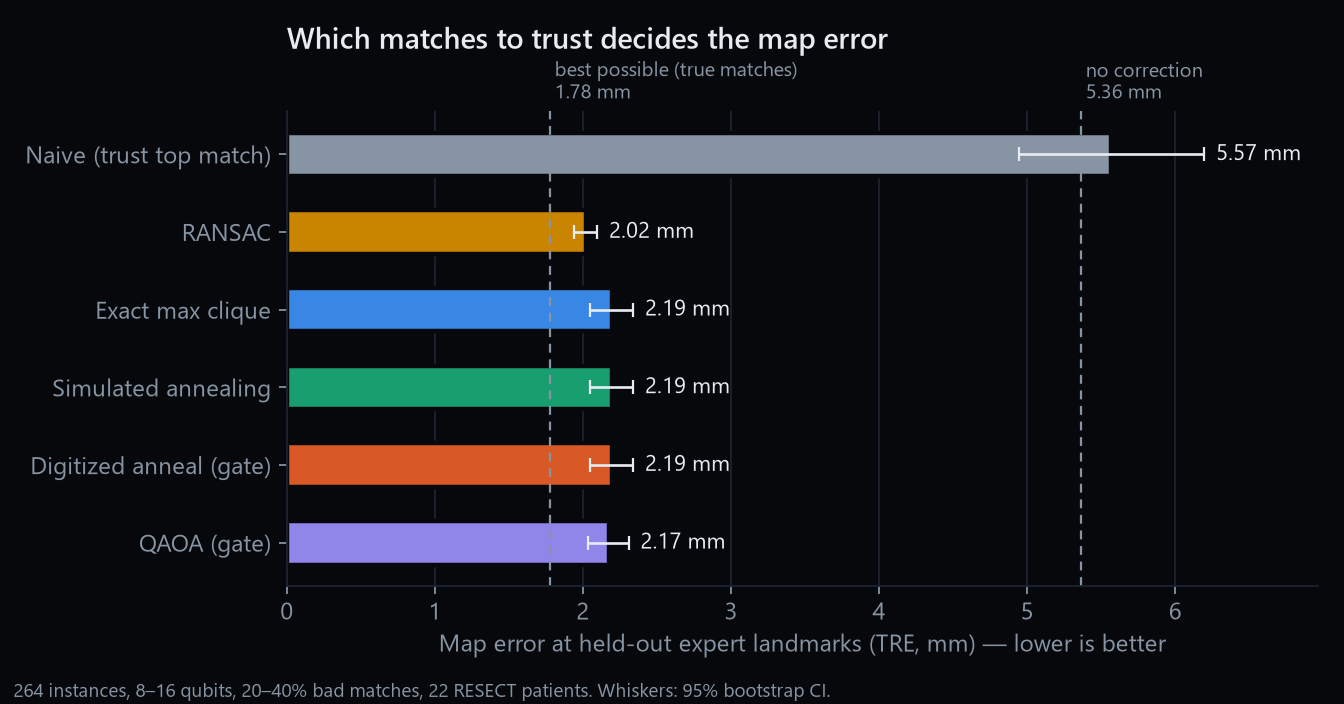

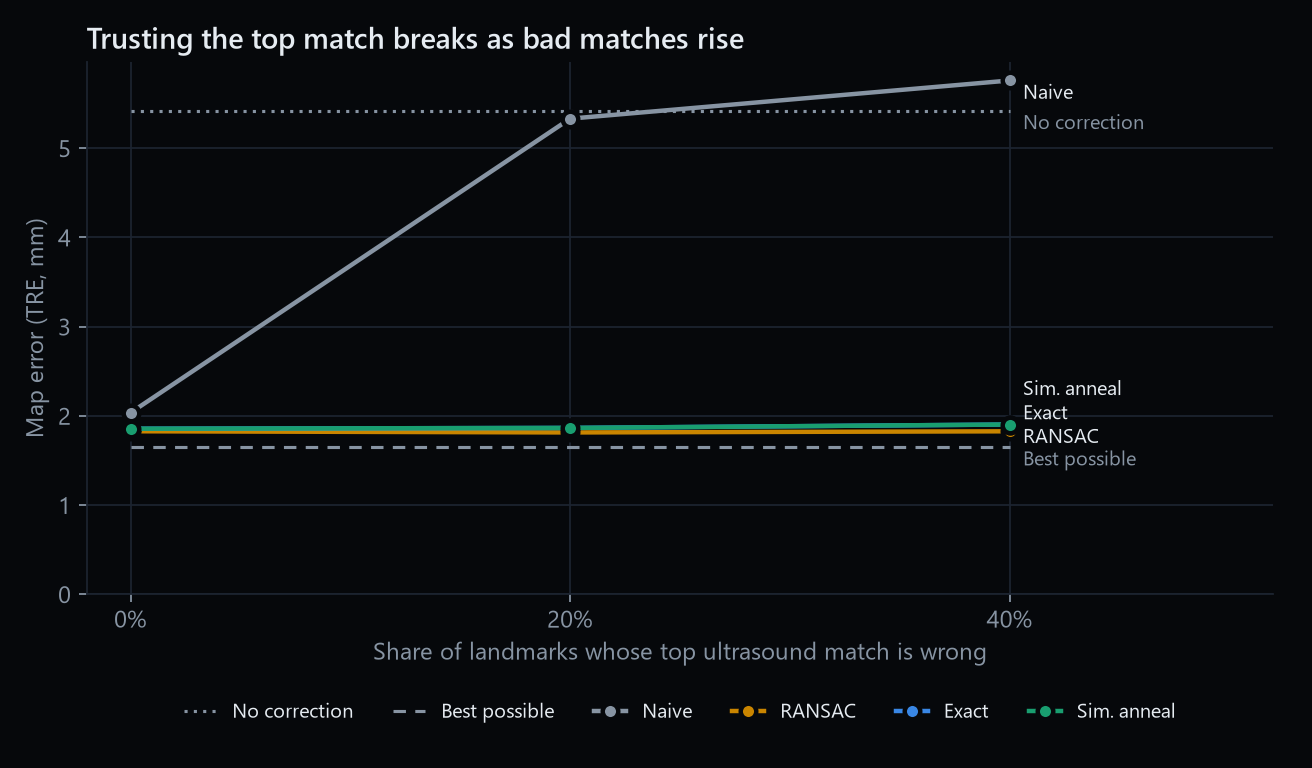

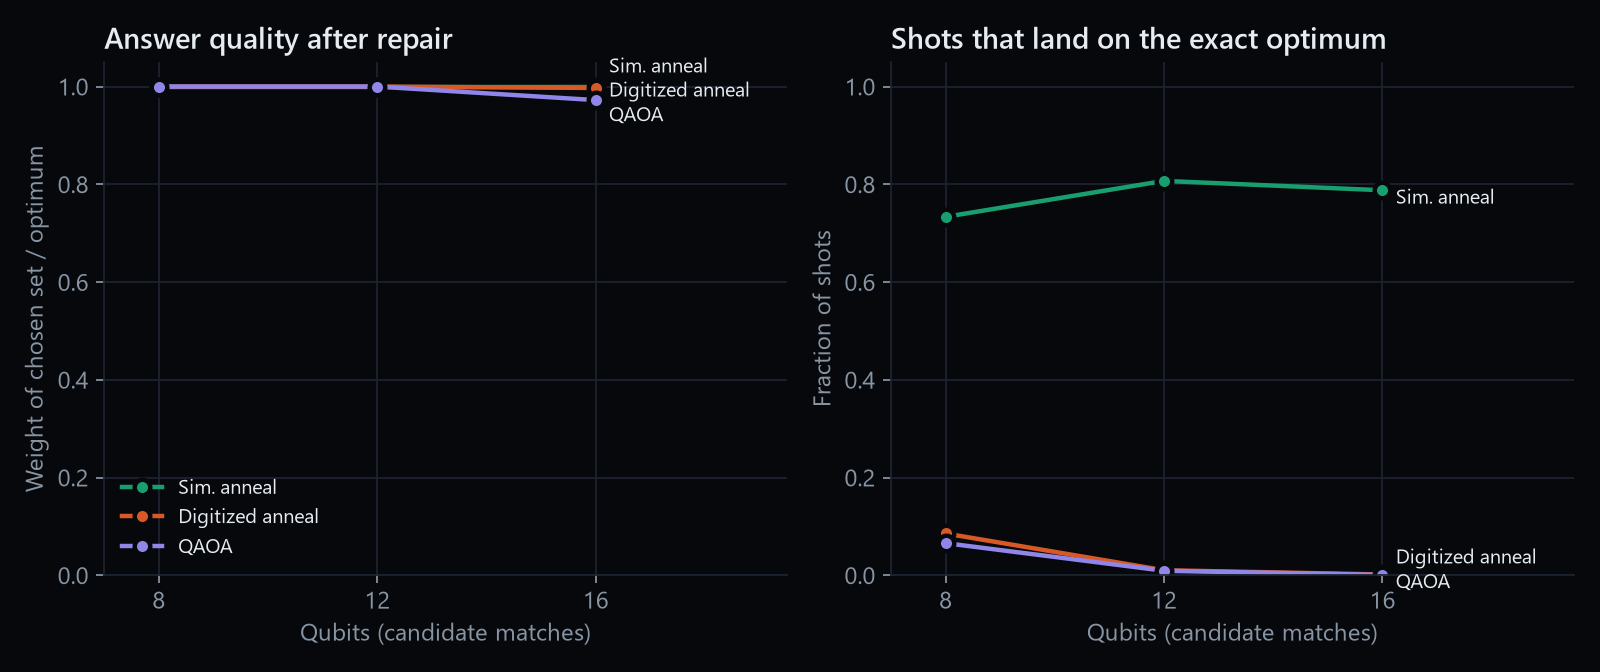

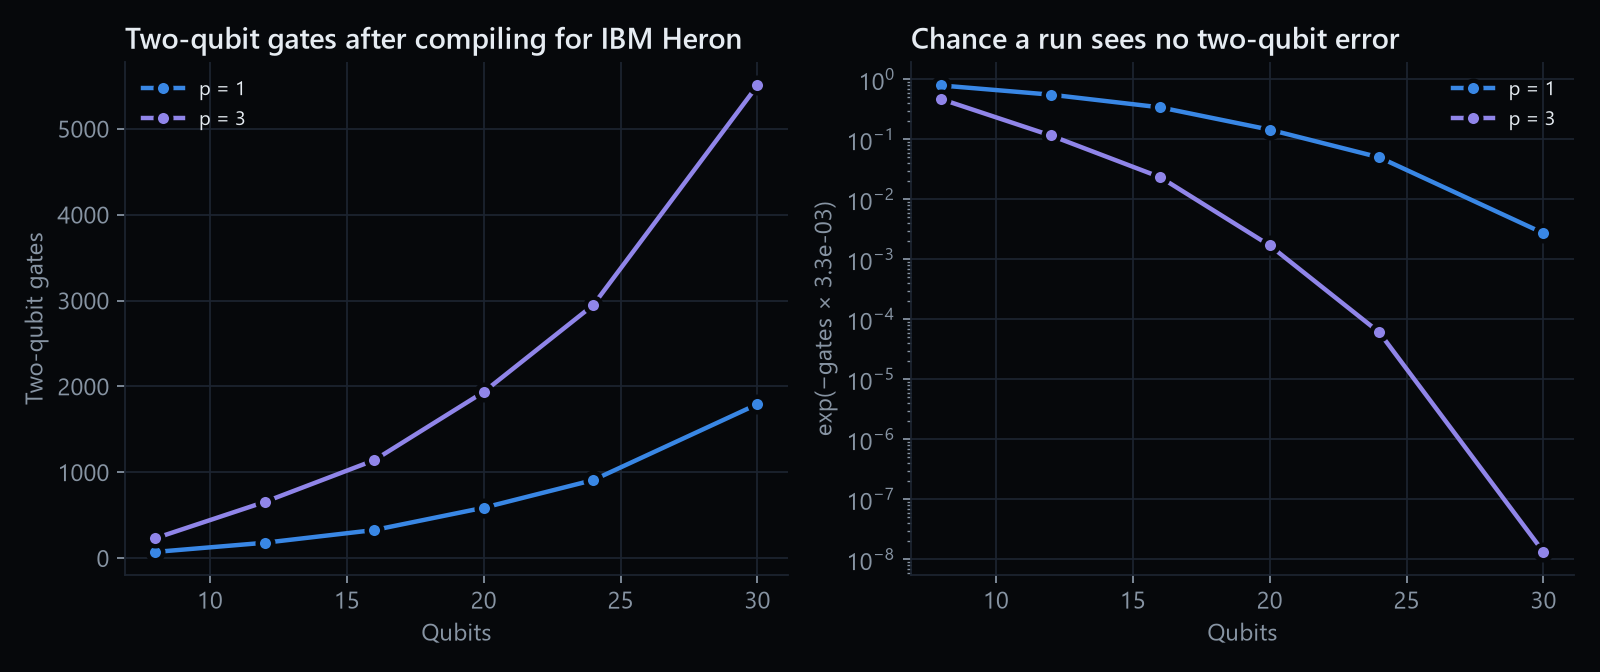

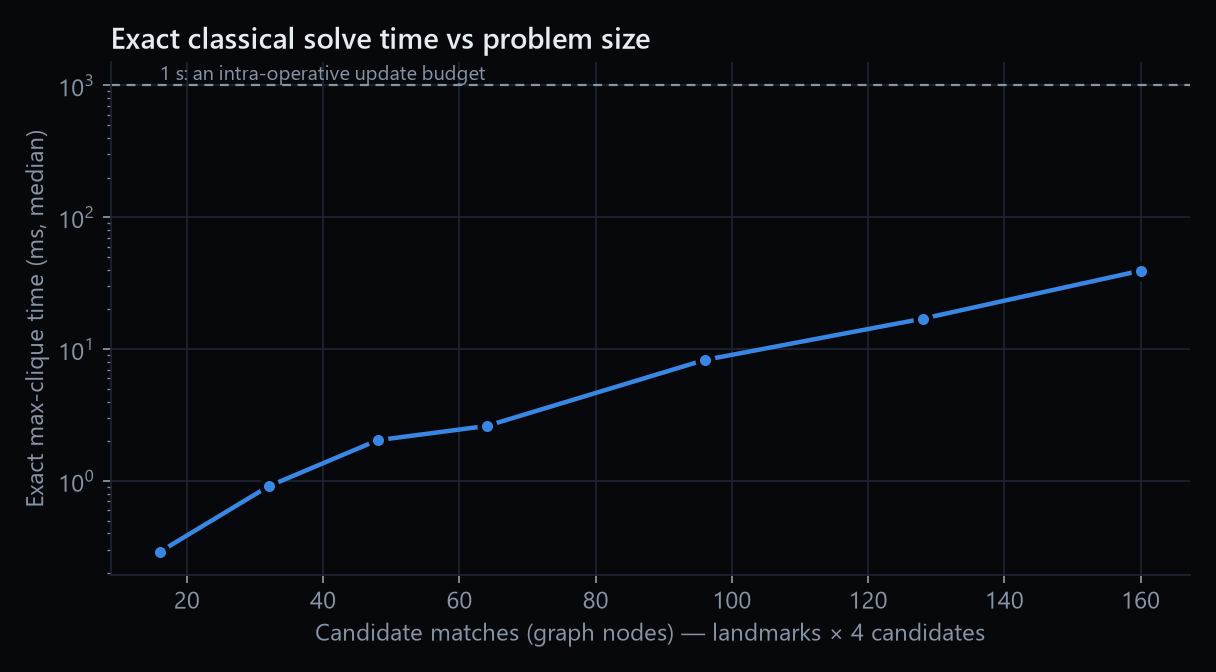

In [7]:
S = json.loads((ROOT / "results/benchmark/summary.json").read_text())
for h in S["headline"]:
    print(f"{h['label']:<26} {h['tre']:.2f} ± {h['tre_ci']:.2f} mm   precision {h['precision']:.3f}")
print()
for k, v in S["paired_tre_difference"].items():
    print(f"{k:<16} {v['mean_mm']:+.3f} ± {v['ci95_mm']:.3f} mm")
for f in S["figures"]:
    display(Image(filename=str(ROOT / "results/figures" / f), width=760))

**What the benchmark says:**
1. Choosing which matches to trust matters: naive 5.6 mm against about 2.2 mm with a consistency check.
2. The quantum solvers match exact max clique on every metric that reaches the surgeon.
3. RANSAC slightly beats the clique formulation. Its global rigid check is stricter than pairwise distance agreement, and we report that as found.
4. Exact classical max clique stays far under a second up to 160 candidates, so **there is no quantum advantage at any size we can run, and we do not claim one.**

## 7. Noise analysis (simulated)
This uses the instances the IBM run will use. Each circuit runs on the ideal simulator and on the IBM Heron noise model (FakeMarrakesh), with uniform random guessing as the floor.

Case12   6q  random 0.179 | qaoa_p1: ideal 0.477 → noisy 0.445 (31 2q gates) | anneal_shallow: ideal 0.792 → noisy 0.715 (70 2q gates) | anneal_deep: ideal 0.864 → noisy 0.719 (177 2q gates)
Case12   8q  random 0.122 | qaoa_p1: ideal 0.555 → noisy 0.505 (45 2q gates) | anneal_shallow: ideal 0.670 → noisy 0.582 (107 2q gates) | anneal_deep: ideal 0.745 → noisy 0.531 (277 2q gates)
Case12  10q  random 0.062 | qaoa_p1: ideal 0.477 → noisy 0.389 (106 2q gates) | anneal_shallow: ideal 0.650 → noisy 0.502 (186 2q gates) | anneal_deep: ideal 0.727 → noisy 0.386 (515 2q gates)
Case12  12q  random 0.020 | qaoa_p1: ideal 0.423 → noisy 0.336 (155 2q gates) | anneal_shallow: ideal 0.519 → noisy 0.289 (379 2q gates) | anneal_deep: ideal 0.615 → noisy 0.127 (1026 2q gates)
Case2    6q  random 0.167 | qaoa_p1: ideal 0.538 → noisy 0.522 (35 2q gates) | anneal_shallow: ideal 0.829 → noisy 0.775 (69 2q gates) | anneal_deep: ideal 0.886 → noisy 0.743 (185 2q gates)
Case2    8q  random 0.085 | qaoa_p1: id

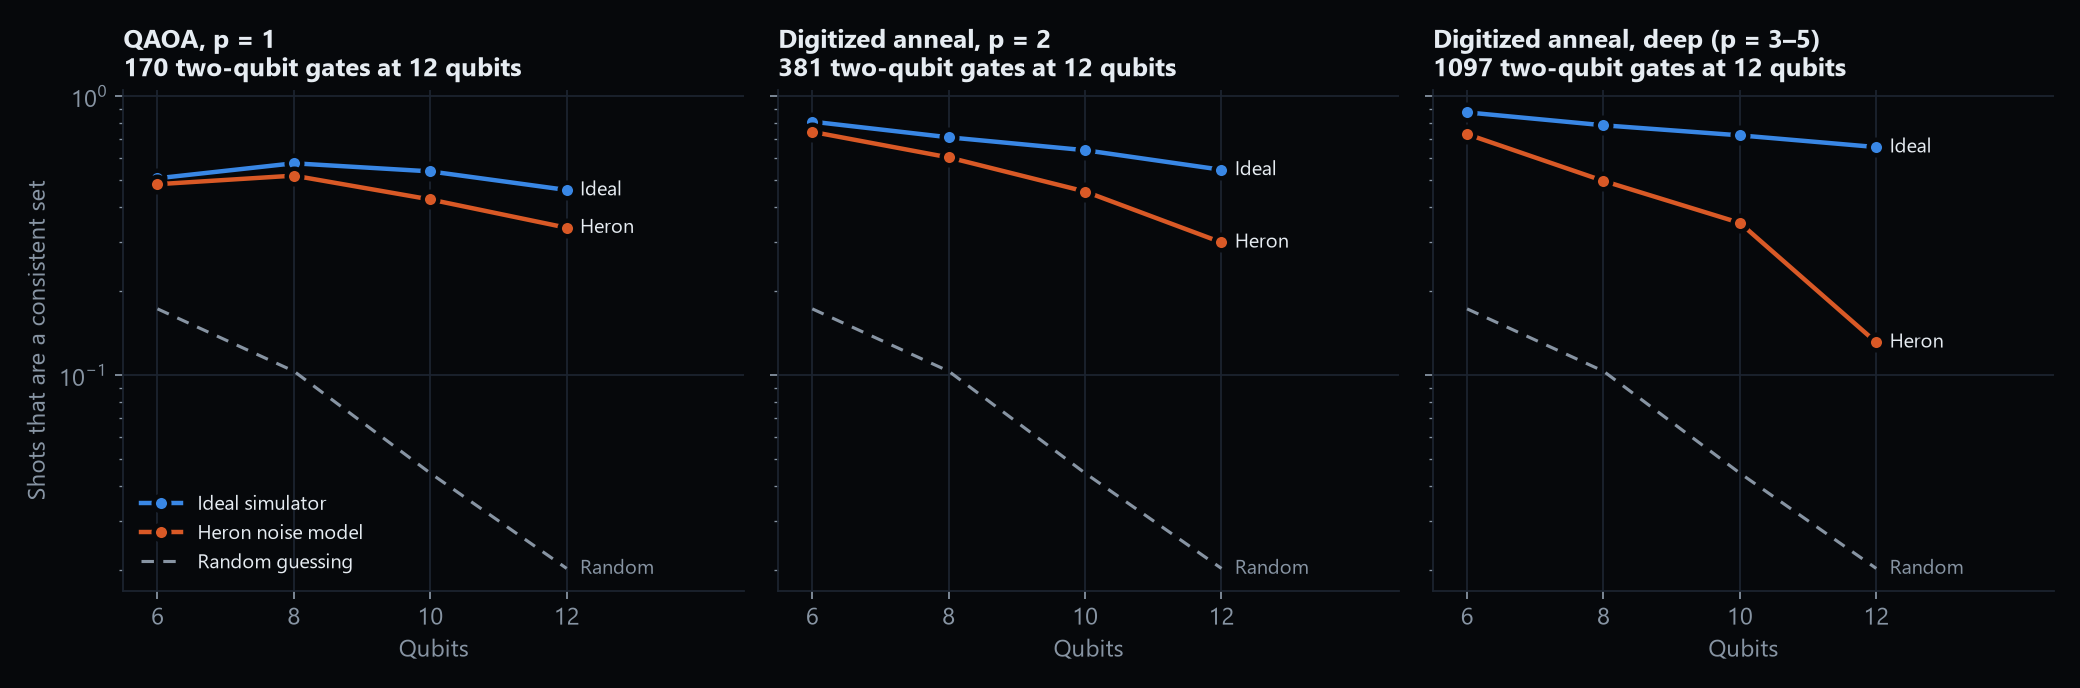

In [8]:
nf = ROOT / "results/noise/summary.json"
if nf.exists():
    N = json.loads(nf.read_text())
    for r in N["instances"]:
        parts = [f"{k}: ideal {m['ideal']['p_feasible']:.3f} → noisy {m['noisy']['p_feasible']:.3f} ({m['two_qubit_gates']} 2q gates)"
                 for k, m in r["methods"].items()]
        print(f"{r['case_id']:<7}{r['qubits']:>3}q  random {r['random']['p_feasible']:.3f} | " + " | ".join(parts))
    display(Image(filename=str(ROOT / "results/figures/noise.png"), width=760))
else:
    print("run scripts/run_noise.py")

## 8. Real hardware (recorded runs, re-scored from raw bitstrings)

In [9]:
from anchor import hwset
from anchor.solvers import summarise_samples
files = sorted((ROOT / "results/hardware").glob("*.json")) if (ROOT / "results/hardware").exists() else []
if not files:
    print("No hardware runs recorded yet (scripts/run_hardware.py, run only with the team's go).")
for f in files:
    rec = json.loads(f.read_text())
    for run in rec["runs"]:
        pp = run["problem"]
        case_h, prob_h, inst_h = hwset.build(pp["case_id"], pp["n_used"], pp["seed"])
        res = summarise_samples(inst_h, np.array(run["samples"]["bits"], bool), np.array(run["samples"]["counts"], float), run["solver"], 0)
        ev = evaluate(case_h, prob_h, res.selection)
        print(f"{run['backend']:<16}{inst_h.m:>3}q {run['label']:<34} consistent shots {res.p_feasible:.3f}  "
              f"optimal {res.p_optimal:.3f}  map error {ev.tre:.2f} mm  job {run['job_id']}")

No hardware runs recorded yet (scripts/run_hardware.py, run only with the team's go).


## 9. Where this goes
The QUBO is the right shape for the problem, and it runs end to end today. That holds on real patient data, on simulators, and on real quantum hardware.

At today's error rates, a 30-qubit instance has well under 1% error-free runs (`summary.json → revisit_trigger`). A clinical case needs 50–200 qubits. Anchor is built so that when two-qubit error rates fall by an order of magnitude, the solver can be swapped and nothing else changes. The benchmark harness is what will tell us when that happens.